## 구글 인공지능에 주문

일부 수정.

In [38]:
# %% [markdown]
# ## IS-LM 모형과 AD-AS 모형의 연계 시뮬레이션

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider


## 모형 파라메타 설정

In [39]:

# 1. 기초 경제 파라미터 (고정값)
c0, c1 = 200, 0.75   # 기초소비, 한계소비성향
i0, i1 = 300, 1000   # 기초투자, 투자의 이자율 민감도
T = 200             # 세금
l1, l2 = 0.5, 1500   # 화폐수요의 소득/이자율 민감도

# 정책 변수들의 시작점
G = 400
M = 600

# 범위 설정
Y_vals = np.linspace(1200, 3000, 1000)
P_vals = np.linspace(0.4, 2.5, 1000)

# 단기 총공급(SRAS) 곡선 설정 (기초 물가와 공급 능력 반영)
# P = P_expected + gamma * (Y - Y_potential)
Y_pot = 2000          # 잠재 산출량 (단기적 기준점)
gamma = 0.0 # 0.0015       # SRAS 곡선의 기울기, 필요시 플러스로.
P_expect = 1.0       # 예상 물가 수준



## IS, LM, AD 함수 찾기
IS-LM, AD 그래프

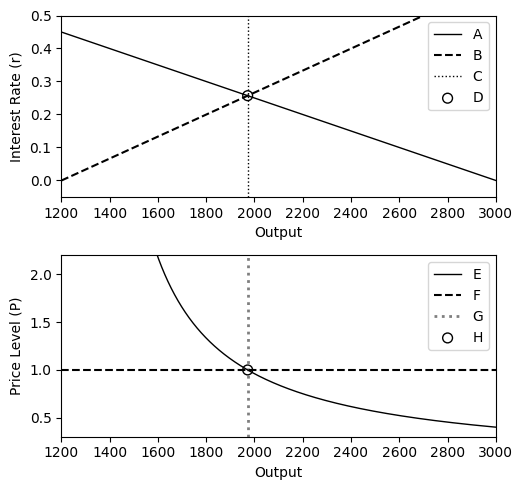

In [49]:
# 2. 실시간 업데이트 함수 정의
#def simulate_macro(G, M) :  # (G=400, M=600):
# --- 1) AD(총수요) 및 균형 계산 ---
# IS-LM 연립방정식에서 P와 Y의 관계(AD 곡선) 도출
# Y = [ l2*(c0 - c1*T + i0 + G) + i1*M/P ] / [ i1*l1 + l2*(1-c1) ]
denom = i1 * l1 + l2 * (1 - c1)
num_fixed = l2 * (c0 - c1 * T + i0 + G)

# AD 곡선 공식 (P에 따른 Y 계산, P_vals 계열)
Y_AD = (num_fixed + i1 * M / P_vals) / denom

# AD와 SRAS의 교점 (종합 균형 물가 P_eq와 균형 소득 Y_eq) 구하기
# 연립방정식: P = P_expect + gamma*(Y - Y_pot) & Y에서 P_eq 도출
# 수치적으로 교점 계산, 단기에는 사실 고정값, AS가 우상향할 때 뒷 부분 반영.
idx = np.nanargmin(np.abs(P_vals - (P_expect + gamma * ((num_fixed + i1 * M / P_vals) / denom - Y_pot))))
P_eq = P_vals[idx]
Y_eq = (num_fixed + i1 * M / P_eq) / denom

# 해당 균형 물가(P_eq) 하에서의 IS-LM 균형 이자율 계산
r_eq = (l1 * Y_eq - M / P_eq) / l2

# --- 2) 시각화 (2개의 서브플롯) ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16/3, 10/2),  )

# [위 그래프: IS-LM 명목 균형]
r_IS = (c0 - c1 * T + i0 + G - (1 - c1) * Y_vals) / i1
r_LM = (l1 * Y_vals - M / P_eq) / l2                    # 결정된 P_eq가 LM의 실질 통화량에 반영됨

ax1.plot(Y_vals, r_IS, label='A', color='black', linewidth=1)
ax1.plot(Y_vals, r_LM, label=f'B', color='black', linestyle='--', linewidth=1.5)
ax1.axvline(Y_eq, color='black', linestyle='dotted', lw=1, label='C')
#ax1.axhline(r_eq, color='black', linestyle='dotted', lw=1) #alpha=0.3,
ax1.scatter(Y_eq, r_eq, color='None', edgecolor='black', s=50, label='D', zorder=5)

#ax1.set_title('1. IS-LM Market Equilibrium', fontsize=12, fontweight='bold')
ax1.set_xlabel('Output')
ax1.set_ylabel('Interest Rate (r)')
ax1.set_xlim(1200, 3000)
ax1.set_ylim(-0.05, 0.50)
#ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right')

# [아래 그래프: AD-AS 물가-산출량 균형]
# 위에서 구한 Y_AD는 P_vals에 대응하므로 X축이 Y_AD, Y축이 P_vals
ax2.plot(Y_AD, P_vals, label='E', color='black', linewidth=1)

# SRAS 곡선 (Y_vals에 따른 P 계산)
P_SRAS = P_expect + gamma * (Y_vals - Y_pot)
ax2.plot(Y_vals, P_SRAS, label='F', color='black', linestyle='--', linewidth=1.5)

# 균형점 표시
ax2.axvline(Y_eq, color='black', linestyle='dotted',  lw=2, label='G', alpha=0.5) #
ax2.scatter(Y_eq, P_eq, color='None', edgecolor='black',s=50, zorder=5,
                label=f'H')
#    ax2.axhline(P_eq, color='gray', linestyle='-.-', alpha=0.5, lw=0.5)

#ax2.set_title('2. AD-AS Aggregate Market', fontsize=12, fontweight='bold')
ax2.set_xlabel('Output')
ax2.set_ylabel('Price Level (P)')
ax2.set_xlim(1200, 3000)
ax2.set_ylim(0.3, 2.2)
#ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()


## 총수요: IS-LM 균형에서 $ Y $와 $ P $의 관계.

\begin{align}
Y &= { c_0 - c_1\times T_0 + i_0 + G_0 + (i_1/l_2) \times (M_0/P)  
                        \over  (1 - c_1) + (i_1/l_2\times l_1)  }
\end{align}

## 총공급 SRAS, LRAS
SRAS P=P^* + 0 *(Y-y^*)
LRAS Y=Y^*

## function 활용법

In [41]:

# 2. 실시간 업데이트 함수 정의
def simulate_macro(G, M) :  # (G=400, M=600):
    # --- 1) AD(총수요) 및 균형 계산 ---
    # IS-LM 연립방정식에서 P와 Y의 관계(AD 곡선) 도출
    # Y = [ l2*(c0 - c1*T + i0 + G) + i1*M/P ] / [ i1*l1 + l2*(1-c1) ]
    denom = i1 * l1 + l2 * (1 - c1)
    num_fixed = l2 * (c0 - c1 * T + i0 + G)

    # AD 곡선 공식 (P에 따른 Y 계산)
    Y_AD = (num_fixed + i1 * M / P_vals) / denom

    # AD와 SRAS의 교점 (종합 균형 물가 P_eq와 균형 소득 Y_eq) 구하기
    # 연립방정식: P = P_expect + gamma*(Y - Y_pot) & Y에서 P_eq 도출
    # 수치적으로 교점 계산
    idx = np.nanargmin(np.abs(P_vals - (P_expect + gamma * ((num_fixed + i1 * M / P_vals) / denom - Y_pot))))
    P_eq = P_vals[idx]
    Y_eq = (num_fixed + i1 * M / P_eq) / denom

    # 해당 균형 물가(P_eq) 하에서의 IS-LM 균형 이자율 계산
    r_eq = (l1 * Y_eq - M / P_eq) / l2

    # --- 2) 시각화 (2개의 서브플롯) ---
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16/3, 10/2),  )

    # [위 그래프: IS-LM 명목 균형]
    r_IS = (c0 - c1 * T + i0 + G - (1 - c1) * Y_vals) / i1
    r_LM = (l1 * Y_vals - M / P_eq) / l2  # 결정된 P_eq가 LM의 실질 통화량에 반영됨

    ax1.plot(Y_vals, r_IS, label='A', color='black', linewidth=1)
    ax1.plot(Y_vals, r_LM, label=f'B', color='black', linestyle='--', linewidth=1)
    ax1.scatter(Y_eq, r_eq, color='None', edgecolor='black', s=50, zorder=5)
    ax1.axvline(Y_eq, color='gray', linestyle='--', alpha=0.3, lw=0.5)
    ax1.axhline(r_eq, color='gray', linestyle='--', alpha=0.3, lw=0.5)

    #ax1.set_title('1. IS-LM Market Equilibrium', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Output')
    ax1.set_ylabel('Interest Rate (r)')
    ax1.set_xlim(1200, 3000)
    ax1.set_ylim(-0.05, 0.50)
    #ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(loc='upper right')

    # [아래 그래프: AD-AS 물가-산출량 균형]
    # 위에서 구한 Y_AD는 P_vals에 대응하므로 X축이 Y_AD, Y축이 P_vals
    ax2.plot(Y_AD, P_vals, label='C', color='black', linewidth=1)

    # SRAS 곡선 (Y_vals에 따른 P 계산)
    P_SRAS = P_expect + gamma * (Y_vals - Y_pot)
    ax2.plot(Y_vals, P_SRAS, label='D', color='black', linestyle='--', linewidth=1)

    # 균형점 표시
    ax2.axvline(Y_eq, color='black', linestyle=':',  lw=2, label='E', alpha=0.5) #
    ax2.scatter(Y_eq, P_eq, color='None', edgecolor='black',s=50, zorder=5,
                label=f'F')
#    ax2.axhline(P_eq, color='gray', linestyle='--', alpha=0.5, lw=0.5)

    #ax2.set_title('2. AD-AS Aggregate Market', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Output')
    ax2.set_ylabel('Price Level (P)')
    ax2.set_xlim(1200, 3000)
    ax2.set_ylim(0.3, 2.2)
    #ax2.grid(True, linestyle=':', alpha=0.6)
    ax2.legend(loc='upper right')

    plt.tight_layout()
    plt.show()


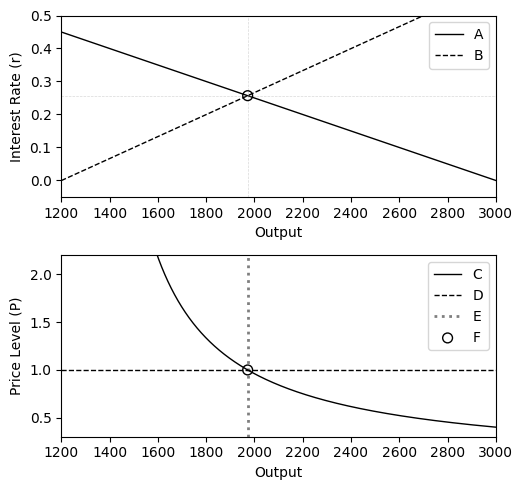

In [42]:

simulate_macro(G, M)
